# Масштабирование и предобработка данных
**Датасет:** Kickstarter Projects (ks-projects-201801.csv).  
**Задача:** подготовить признаки для прогнозирования успеха проекта.

Сравним несколько способов масштабирования цели сбора и обработаем остальные столбцы.
Перед подбором параметров разделим данные на train и test в отношении 80/20.

## 1 Загрузка данных и библиотек
Используем тот же датасет, что и в прошлой работе. Одна строка - один проект Kickstarter.
Файл `ks-projects-201801.csv` должен лежать в одной папке с блокнотом.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

SEED = 42
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 30)

In [2]:
raw = pd.read_csv(Path('ks-projects-201801.csv'))
print('Исходный размер:', raw.shape)

Исходный размер: (378661, 15)


In [3]:
display(raw.head())
display(pd.DataFrame({'тип': raw.dtypes.astype(str), 'пропуски': raw.isna().sum(),
                      'уникальных': raw.nunique()}))
print('Полные дубликаты:', raw.duplicated().sum())
print('Повторы ID:', raw.ID.duplicated().sum())
print('Повторы названия (не основание удаления):', raw.name.duplicated().sum())

Полные дубликаты: 0
Повторы ID: 0
Повторы названия (не основание удаления): 2896


,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhoo...,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


,тип,пропуски,уникальных
ID,int64,0,378661
name,object,4,375764
category,object,0,159
main_category,object,0,15
currency,object,0,14
deadline,object,0,3164
goal,float64,0,8353
launched,object,0,378089
pledged,float64,0,62130
state,object,0,6


## 2 Очистка данных
Проверяем данные по шагам. После каждого удаления выводим число удалённых и оставшихся строк.

In [4]:
# Работаем с копией, чтобы исходные данные остались доступны.
d = raw.copy()
log = []  # сюда записываем число удалённых строк
repairs = []  # сюда записываем исправления пропусков

### 2.1 Дубликаты
Удаляем полные копии. ID должен быть уникальным. Одинаковые названия разных проектов оставляем: это могут быть разные кампании или повторные запуски.

In [5]:
before = len(d)
d = d.loc[~d.duplicated()].copy()  # оставляем подходящие строки
log.append({'правило': 'Полные дубликаты', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))
assert d.ID.notna().all(), 'Пропущен ключ: нужна проверка источника'
assert d.ID.is_unique, 'Конфликт ID: нужна ручная проверка'

Удалено: 0 Осталось: 378661


### 2.2 Числовые значения
Цель должна быть больше нуля, сборы и число спонсоров - неотрицательными. Число спонсоров должно быть целым. Неправильные значения и пропуски в этих полях удаляем.

In [6]:
numeric = ['goal', 'usd_goal_real', 'pledged', 'usd_pledged_real', 'backers']
for col in numeric:
    d[col] = pd.to_numeric(d[col], errors='coerce')
for col in ['launched', 'deadline']:
    d[col] = pd.to_datetime(d[col], errors='coerce')
valid_numbers = np.isfinite(d[numeric]).all(axis=1)
valid_numbers &= (d[['goal', 'usd_goal_real']] > 0).all(axis=1)
valid_numbers &= (d[['pledged', 'usd_pledged_real', 'backers']] >= 0).all(axis=1)
valid_numbers &= d.backers.eq(np.floor(d.backers))
before = len(d)
d = d.loc[valid_numbers].copy()  # оставляем подходящие строки
log.append({'правило': 'Некорректные числа / обязательные значения', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))

Удалено: 0 Осталось: 378661


### 2.3 Даты
Оставляем даты запуска с 2009 года по январь 2018 года - период исходного датасета. Дедлайн не должен быть раньше даты запуска. Сравниваем календарные даты, потому что время дедлайна не указано.

In [7]:
valid_dates = d.launched.between('2009-01-01', '2018-01-31 23:59:59')
valid_dates &= d.deadline.notna() & (d.deadline >= d.launched.dt.normalize())
before = len(d)
d = d.loc[valid_dates].copy()  # оставляем подходящие строки
log.append({'правило': 'Ошибка даты запуска или порядка дат', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))

Удалено: 7 Осталось: 378654


### 2.4 Статус проекта
Как и раньше, оставляем successful и failed. Отменённые, заблокированные и ещё идущие кампании не подходят для нашей бинарной задачи.

In [8]:
before = len(d)
d = d.loc[d.state.isin(['successful', 'failed'])].copy()  # оставляем подходящие строки
log.append({'правило': 'Вне бинарной задачи', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))

Удалено: 46979 Осталось: 331675


### 2.5 Совпадение статуса и суммы
Успешный проект должен собрать не меньше цели, провалившийся - меньше. Сравниваем суммы в исходной валюте. Противоречивые строки удаляем: даже если небольшая разница вызвана округлением, исправлять статус без исходных данных нельзя.

In [9]:
mismatch = ((d.state.eq('successful') & d.pledged.lt(d.goal)) |
            (d.state.eq('failed') & d.pledged.ge(d.goal)))
conflicts = d.loc[mismatch, ['ID', 'state', 'goal', 'pledged']].copy()
before = len(d)
d = d.loc[~mismatch].copy()  # оставляем подходящие строки
log.append({'правило': 'Статус противоречит сумме', 'удалено': before-len(d), 'осталось': len(d)})
print('Удалено:', before-len(d), 'Осталось:', len(d))
display(conflicts)  # строки с противоречивым статусом

Удалено: 11 Осталось: 331664


,ID,state,goal,pledged
16780,1085047405,failed,23000.0,23020.01
58558,1297794474,failed,3000.0,3087.50
72483,1368992939,successful,3600.0,3599.69
136909,1695255515,failed,3600.0,3600.00
151490,1769772834,successful,36000.0,30716.00
216545,2103203254,failed,10000.0,10797.00
232422,251325270,successful,8000.0,7999.65
275777,4732285,successful,2000.0,1999.66
298960,59246799,failed,6000.0,6183.00
335859,780863434,successful,25000.0,24892.50


### 2.6 Пропуски в названии
Отсутствующее название заменяем пустой строкой. Так при подсчёте длины названия получим 0.

In [10]:
missing_name = d.name.isna() | d.name.fillna('').str.strip().eq('')
repairs.append({'поле': 'name', 'исправлено': int(missing_name.sum()), 'действие': 'Пустая строка'})
d['name'] = d.name.fillna('').str.strip()
print('Заполнено названий:', int(missing_name.sum()))

Заполнено названий: 3


### 2.7 Страна и другие категории
Ошибочную страну `N,0"` и пустые категории заменяем на `Unknown`. Угадать правильное значение по остальным полям нельзя.

In [11]:
for col in ['country', 'currency', 'category', 'main_category']:
    d[col] = d[col].astype('string').str.strip().replace({'': pd.NA, 'N,0"': pd.NA})
    repairs.append({'поле': col, 'исправлено': int(d[col].isna().sum()), 'действие': 'Unknown'})
    d[col] = d[col].fillna('Unknown').astype(str)
display(pd.DataFrame(repairs))

,поле,исправлено,действие
0,name,3,Пустая строка
1,country,210,Unknown
2,currency,0,Unknown
3,category,0,Unknown
4,main_category,0,Unknown


### 2.8 Повторяющийся показатель сбора
Удаляем `usd pledged`: это ещё одна запись итогового сбора, в исходном файле у неё 3797 пропусков. Другие USD-столбцы рассчитаны по другому курсу, поэтому заполнять ими пропуски некорректно.

In [12]:
repairs.append({'поле': 'usd pledged', 'исправлено': int(d['usd pledged'].isna().sum()),
                'действие': 'Удалён дублирующий итоговый столбец'})
d = d.drop(columns=['usd pledged'])
print('Столбец usd pledged удалён')

Столбец usd pledged удалён


### 2.9 Длительность и целевая переменная
Считаем длительность в календарных днях. Успешному проекту присваиваем target = 1, провалившемуся - 0. Очень большие положительные цели оставляем: сами по себе они не ошибка.

In [13]:
d['duration_days'] = (d.deadline - d.launched.dt.normalize()).dt.days
d['target'] = d.state.eq('successful').astype('int8')
assert d.ID.is_unique and not d.isna().any().any()
assert (d.duration_days >= 0).all()

### 2.10 Итог очистки
Проверяем пропуски и смотрим, сколько строк убрало каждое правило. Одна строка учитывается только при первом удалении.

In [14]:
clean = d.copy()
cleaning_log = pd.DataFrame(log)
repairs = pd.DataFrame(repairs)
display(cleaning_log)
display(repairs)
print('Осталось строк:', len(clean))
print('Пропусков:', clean.isna().sum().sum())
print('Доля успешных:', round(clean.target.mean(), 4))

Осталось строк: 331664
Пропусков: 0
Доля успешных: 0.4039


,правило,удалено,осталось
0,Полные дубликаты,0,378661
1,Некорректные числа / обязательные значения,0,378661
2,Ошибка даты запуска или порядка дат,7,378654
3,Вне бинарной задачи,46979,331675
4,Статус противоречит сумме,11,331664


,поле,исправлено,действие
0,name,3,Пустая строка
1,country,210,Unknown
2,currency,0,Unknown
3,category,0,Unknown
4,main_category,0,Unknown
5,usd pledged,210,Удалён дублирующий итоговый столбец


## 3 Разделение на train и test
По заданию берём 80% для обучения и 20% для теста. `stratify` сохраняет примерно одинаковую долю успешных проектов в обеих частях.

Это отдельное разбиение для предобработки, не 25/75 из первой части. Средние, медианы и параметры преобразований считаем только на train. К test применяем уже готовые преобразования.
Здесь мы готовим данные, качество модели пока не оцениваем.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, FunctionTransformer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

train, test = train_test_split(clean, test_size=0.20, random_state=SEED, stratify=clean.target)
assert set(train.ID).isdisjoint(set(test.ID))
assert len(train) + len(test) == len(clean)
display(pd.DataFrame({'строк': [len(train), len(test)],
                      'доля': [len(train)/len(clean), len(test)/len(clean)],
                      'доля_успеха': [train.target.mean(), test.target.mean()]}, index=['train', 'test']))

,строк,доля,доля_успеха
train,265331,0.799999,0.403877
test,66333,0.200001,0.403871


## 4 Масштабирование цели сбора
Выбрали `usd_goal_real`: цель уже переведена в доллары, но значения сильно различаются.

- **StandardScaler** вычитает среднее и делит на стандартное отклонение. Большие выбросы влияют на оба значения.
- **MinMaxScaler** переводит значения train в диапазон от 0 до 1. При большом максимуме большинство значений окажется около нуля. Значения test могут выйти за этот диапазон.
- **RobustScaler** вычитает медиану и делит на разницу между 75-м и 25-м процентилями. Такой масштаб меньше зависит от выбросов.
- **log1p + StandardScaler** сначала берёт `ln(1 + x)`, затем стандартизирует результат. Логарифм сжимает большие значения.

Сравним среднее, медиану и асимметрию. Асимметрия показывает, насколько распределение скошено. Первые три метода меняют масштаб, но не форму распределения.

In [16]:
goal_train = train[['usd_goal_real']]
goal_test = test[['usd_goal_real']]
scalers = {
    'StandardScaler': StandardScaler(),
    'MinMaxScaler': MinMaxScaler(),
    'RobustScaler': RobustScaler(),
    'log1p + StandardScaler': Pipeline([
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scale', StandardScaler())])
}
transformed = {'Исходный USD': goal_train.to_numpy().ravel()}
transformed_test = {}
for label, scaler in scalers.items():
    transformed[label] = scaler.fit_transform(goal_train).ravel()
    transformed_test[label] = scaler.transform(goal_test).ravel()

### 4.2 Сравнение числовых характеристик
Для каждого метода считаем среднее, медиану, разброс и асимметрию.

In [17]:
scale_rows = []
for label, values in transformed.items():
    s = pd.Series(values)
    q01, q99 = s.quantile([0.01, 0.99])
    scale_rows.append({'метод': label, 'среднее': s.mean(), 'медиана': s.median(),
        'std_ddof0': s.std(ddof=0), 'асимметрия': s.skew(), 'min': s.min(), 'max': s.max(),
        'q01': q01, 'q99': q99, 'доля_размаха_1_99': (q99-q01)/(s.max()-s.min())})
scale_summary = pd.DataFrame(scale_rows).set_index('метод')
display(scale_summary.round(5))

,среднее,медиана,std_ddof0,асимметрия,min,max,q01,q99,доля_размаха_1_99
метод,,,,,,,,,
Исходный USD,41436.12460,5000.00000,1.084095e+06,82.76003,0.01000,1.663614e+08,78.86600,300000.00000,0.00180
StandardScaler,0.00000,-0.03361,1.000000e+00,82.76003,-0.03822,1.534182e+02,-0.03815,0.23851,0.00180
MinMaxScaler,0.00025,0.00003,6.520000e-03,82.76003,0.00000,1.000000e+00,0.00000,0.00180,0.00180
RobustScaler,2.80278,0.00000,8.339195e+01,82.76003,-0.38461,1.279665e+04,-0.37855,22.69231,0.00180
log1p + StandardScaler,0.00000,-0.03820,1.000000e+00,-0.14077,-5.13996,6.205850e+00,-2.51911,2.41699,0.43506


## 5 Графики до и после преобразований
Слева показаны все значения train. Справа - центральные 98%, чтобы лучше увидеть основную часть распределения. Это ограничение только для графика: строки из данных не удаляем.

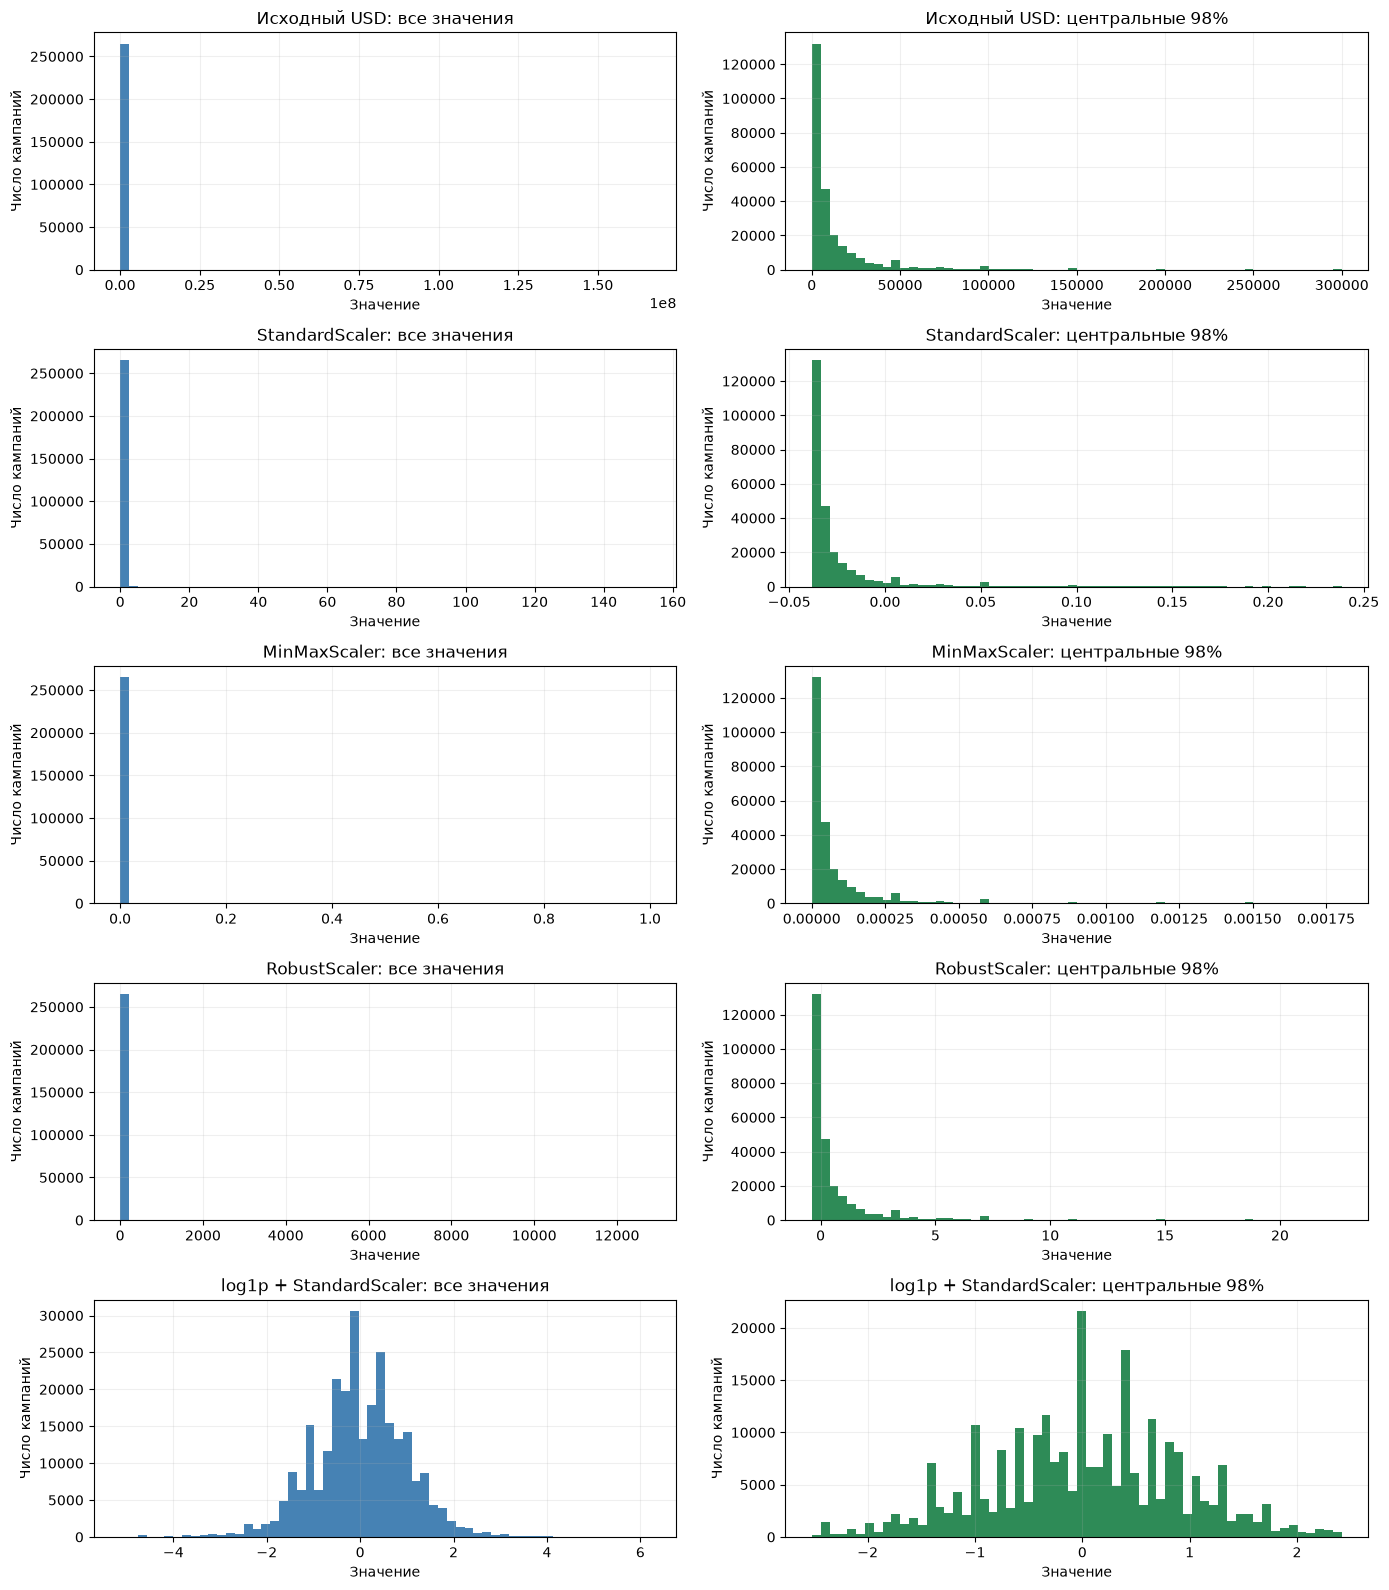

In [18]:
fig, axes = plt.subplots(len(transformed), 2, figsize=(14, 16))
for row, (label, values) in enumerate(transformed.items()):
    lo, hi = np.quantile(values, [0.01, 0.99])
    axes[row, 0].hist(values, bins=60, color='steelblue')
    axes[row, 0].set(title=f'{label}: все значения', xlabel='Значение', ylabel='Число кампаний')
    central = values[(values >= lo) & (values <= hi)]
    axes[row, 1].hist(central, bins=60, color='seagreen')
    axes[row, 1].set(title=f'{label}: центральные 98%', xlabel='Значение', ylabel='Число кампаний')
plt.tight_layout()
plt.show()

## 6 Сравнение методов и выбор

In [19]:
before = scale_summary.loc['Исходный USD', 'асимметрия']
after = scale_summary.loc['log1p + StandardScaler', 'асимметрия']
display(Markdown(f'**Выбор: log1p + StandardScaler.** Асимметрия train меняется с **{before:.2f}** '
    f'до **{after:.2f}**. Обычная стандартизация меняет единицы, но сохраняет длинный хвост; '
    'MinMax сжимает большинство небольших целей около нуля; RobustScaler устойчиво определяет '
    'центр, однако не сжимает сами экстремумы. Логарифм делает различия между небольшими '
    'и средними бюджетами заметнее относительно редких огромных целей. '
    'Это выбор по форме train для моделей, чувствительных к масштабу, '
    'а не доказательство лучшего качества любой модели. Для дерева решений масштабирование может быть не нужно.'))
print('MinMax на test: min/max =', transformed_test['MinMaxScaler'].min(), transformed_test['MinMaxScaler'].max())

MinMax на test: min/max = 2.9453949497429874e-09 0.9100421033568576


**Выбор: log1p + StandardScaler.** Асимметрия train меняется с **82.76** до **-0.14**. Обычная стандартизация меняет единицы, но сохраняет длинный хвост; MinMax сжимает большинство небольших целей около нуля; RobustScaler устойчиво определяет центр, однако не сжимает сами экстремумы. Логарифм делает различия между небольшими и средними бюджетами заметнее относительно редких огромных целей. Это выбор по форме train для моделей, чувствительных к масштабу, а не доказательство лучшего качества любой модели. Для дерева решений масштабирование может быть не нужно.

## 7 Предобработка остальных столбцов
Для каждого столбца выбираем обработку по его смыслу.

| Столбец | Что делаем и почему |
|---|---|
| `ID` | Убираем: это номер проекта, он нужен только для проверки дубликатов |
| `name` | Считаем длину, число слов и отмечаем пустое название. Это простой способ получить числовые признаки; смысл текста он не учитывает |
| `main_category`, `category` | One-hot: отдельный столбец 0/1 для каждого значения. У категорий нет числового порядка |
| `country`, `currency` | Тоже one-hot. Страна и валюта могут давать разную информацию |
| `launched` | Получаем год, месяц и день недели запуска |
| `deadline` | Вместе с датой запуска используем для расчёта длительности |
| `usd_goal_real` | Применяем выбранный log1p + StandardScaler |
| `goal` | Убираем: это та же цель, но в разных валютах |
| `pledged`, `usd pledged`, `usd_pledged_real`, `backers` | Убираем: известны после окончания сбора и раскрывают ответ. `usd pledged` уже удалён при очистке |
| `state` | Превращаем в ответ `target`: successful = 1, failed = 0. В признаки не включаем |

Длительность, год, длину названия и число слов стандартизируем. Для возможных пропусков добавляем заполнение медианой train; после нашей очистки пропусков уже нет.

Месяц и день недели кодируем через sin/cos: так декабрь остаётся рядом с январём, а воскресенье - с понедельником. Эти значения уже лежат от -1 до 1, их дополнительно не масштабируем. Признак пустого названия оставляем как 0/1.

`handle_unknown='ignore'` позволяет обработать категорию test, которой не было на train. Все шаги собираем в `ColumnTransformer`, чтобы одинаково обработать обе части.

### 7.1 Новые признаки
Из названия получаем длину и число слов, из даты запуска - год, месяц и день недели. Одни и те же действия применяем к train и test.

In [20]:
def make_features(frame):
    # Только построчные преобразования, никакой оценки параметров по данным.
    out = frame[['usd_goal_real', 'duration_days', 'main_category', 'category', 'country', 'currency']].copy()
    names = frame.name.fillna('')
    out['name_len'] = names.str.len()
    out['name_words'] = names.str.split().str.len()
    out['name_missing'] = names.eq('').astype(int)
    out['launch_year'] = frame.launched.dt.year
    month = frame.launched.dt.month - 1
    weekday = frame.launched.dt.weekday
    out['month_sin'] = np.sin(2*np.pi*month/12)
    out['month_cos'] = np.cos(2*np.pi*month/12)
    out['weekday_sin'] = np.sin(2*np.pi*weekday/7)
    out['weekday_cos'] = np.cos(2*np.pi*weekday/7)
    return out

### 7.2 Группы признаков
Отдельно перечисляем денежную цель, остальные числа, категории и уже ограниченные по масштабу признаки.

In [21]:
X_train, X_test = make_features(train), make_features(test)
y_train, y_test = train.target.copy(), test.target.copy()
log_cols = ['usd_goal_real']
numeric_cols = ['duration_days', 'name_len', 'name_words', 'launch_year']
category_cols = ['main_category', 'category', 'country', 'currency']
pass_cols = ['name_missing', 'month_sin', 'month_cos', 'weekday_sin', 'weekday_cos']
assert set(X_train.columns) == set(log_cols + numeric_cols + category_cols + pass_cols)

### 7.3 Преобразования
Для цели используем логарифм и стандартизацию, для остальных чисел - стандартизацию, для категорий - one-hot.

In [22]:
log_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler())])
numeric_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler())])
category_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=True))])

### 7.4 Объединение преобразований
Указываем, к каким столбцам применить каждый набор действий.

In [23]:
preprocessor = ColumnTransformer([
    ('goal', log_pipeline, log_cols),
    ('numeric', numeric_pipeline, numeric_cols),
    ('category', category_pipeline, category_cols),
    ('bounded', 'passthrough', pass_cols),
], remainder='drop', sparse_threshold=1.0)

### 7.5 Применение к train и test
fit_transform вычисляет параметры по train. transform использует эти параметры для test.

In [24]:
# Единственный fit — на train. Test только преобразуется.
X_train_ready = preprocessor.fit_transform(X_train)
X_test_ready = preprocessor.transform(X_test)

In [25]:
feature_names = preprocessor.get_feature_names_out()
print('Готовые train/test:', X_train_ready.shape, X_test_ready.shape)
print('Число выходных признаков:', len(feature_names))
display(pd.DataFrame(X_train_ready[:5].toarray(), columns=feature_names).iloc[:, :16])

Готовые train/test: (265331, 221) (66333, 221)
Число выходных признаков: 221


,goal__usd_goal_real,numeric__duration_days,numeric__name_len,numeric__name_words,numeric__launch_year,category__main_category_Art,category__main_category_Comics,category__main_category_Crafts,category__main_category_Dance,category__main_category_Design,category__main_category_Fashion,category__main_category_Film & Video,category__main_category_Food,category__main_category_Games,category__main_category_Journalism,category__main_category_Music
0,1.342510,-0.703975,-0.514944,0.134294,0.425868,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.759921,-0.310423,-0.577611,-0.591503,-0.092054,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,-0.038200,-0.310423,-0.765612,-0.954402,-0.092054,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,2.173837,-0.310423,0.174392,-0.228605,0.943790,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,0.163542,-0.310423,1.365064,1.222989,-0.092054,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 8 Проверка результата
Проверяем, что число признаков совпало, пропусков и бесконечностей нет, а проекты train и test не пересекаются.
Параметры заполнения и масштабирования должны соответствовать train.

One-hot создаёт много нулей. Поэтому используем разреженные матрицы: они хранят только ненулевые значения и занимают меньше памяти.

In [26]:
from scipy import sparse
assert sparse.issparse(X_train_ready) and sparse.issparse(X_test_ready)
assert np.isfinite(X_train_ready.data).all() and np.isfinite(X_test_ready.data).all()
assert X_train_ready.shape[1] == X_test_ready.shape[1] == len(feature_names)
assert set(train.ID).isdisjoint(set(test.ID))
assert not {'ID', 'state', 'target', 'pledged', 'usd pledged', 'usd_pledged_real', 'backers'} & set(X_train.columns)
np.testing.assert_allclose(preprocessor.named_transformers_['numeric'].named_steps['impute'].statistics_,
                           X_train[numeric_cols].median().to_numpy())
np.testing.assert_allclose(preprocessor.named_transformers_['goal'].named_steps['scale'].mean_,
                           np.log1p(X_train[log_cols]).mean().to_numpy())
assert preprocessor.named_transformers_['numeric'].named_steps['scale'].n_samples_seen_ == len(train)
probe = X_test.iloc[:1].copy()
probe['country'] = 'NEW_COUNTRY'
assert np.isfinite(preprocessor.transform(probe).data).all()
print('Проверки пройдены. Пропуски и бесконечности в итоговых матрицах отсутствуют.')

Проверки пройдены. Пропуски и бесконечности в итоговых матрицах отсутствуют.


## 9 Выводы
- Для цели сбора выбрали `log1p + StandardScaler`: логарифм уменьшил сильную скошенность вправо, затем значения были приведены к общему масштабу.
- StandardScaler и MinMaxScaler без логарифма сохраняют длинный хвост. RobustScaler меньше зависит от выбросов при расчёте масштаба, но сами большие значения остаются.
- Остальные числовые признаки стандартизировали, категории перевели в one-hot. Из дат и названий получили новые признаки.
- Убрали ID, дублирующую цель в исходной валюте и итоговые показатели сбора, которые раскрывают ответ.
- Получили train и test без пропусков и бесконечностей, по 221 признаку. Параметры преобразований рассчитаны только на train.

Выбор масштабирования сделан по распределению признака. Чтобы сравнить качество моделей с разными методами, нужно отдельно обучить и проверить модели.